# 03 — Entraînement, optimisation et évaluation des modèles

**Rôle :** comparer les algorithmes du cours (Zero-R, K-NN, arbre de décision, Random Forest, Naïve Bayes,
SVM) et des extensions classiques (régression logistique, LDA, Extra Trees, AdaBoost, Gradient Boosting,
XGBoost, vote souple, stacking) sur deux tâches :
- **binaire** : normal vs attaque (priorité au **rappel** : une attaque manquée coûte plus cher qu'une fausse alerte) ;
- **multi-classe** : 10 catégories.

**Protocole :**
1. chaque modèle = `Pipeline(prétraitement → classifieur)` ;
2. `GridSearchCV` (grilles discrètes) ou `RandomizedSearchCV` (espaces continus) avec **`StratifiedKFold(5)`**,
   scoring F1 (binaire) / F1-macro (multi-classe), métriques secondaires enregistrées ;
3. ré-ajustement sur tout le train, évaluation **une seule fois** sur le test ;
4. le modèle déployé est le meilleur en **moyenne sur 5 plis communs à tous les modèles** (y compris vote et stacking) :
   comparaison équitable, sans utiliser le test (choisir sur le test biaiserait l'estimation).

**L'entraînement est réalisé dans ce notebook** : les cellules ci-dessous appellent `src/train.py`
(le même code est exécutable sans Jupyter par `python scripts/train.py`). Budgets de recherche réduits pour
tenir sur une machine de 8 Go de RAM (grilles resserrées, 8 à 10 tirages aléatoires pour les ensembles,
réglage de K-NN et SVM sur sous-échantillon) — documentés dans `src/models.py`. Les résultats sont
sauvegardés après chaque tâche : si l'exécution est interrompue, la relance reprend où elle s'était arrêtée
(`RESUME = True`).

In [1]:
# Configuration : le notebook s'exécute depuis notebooks/, on ajoute la racine du dépôt au chemin
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from src import config as C
from src import visualization as V
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 200)
print('Racine du projet :', ROOT.name)

Racine du projet : Network-Intrusion-Detection-System


In [2]:
from src import train as TE
RESUME = True                      # False : tout ré-entraîner depuis zéro
reg, curves = TE.start(resume=RESUME)
train, test = TE.load_split()
print(f"train : {len(train):,} flux | test : {len(test):,} flux | parallélisme NIDS_JOBS = {TE.N_JOBS}")

train : 73,031 flux | test : 18,258 flux | parallélisme NIDS_JOBS = 2


## 1. Démonstration du mécanisme d'optimisation (exemple K-NN)

Avant de lire les résultats complets, on illustre `GridSearchCV` sur un petit échantillon : étude du
paramètre **K**, de la **distance** (Manhattan p=1, Euclidienne p=2) et de la pondération, avec standardisation.

In [3]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from src.preprocessing import build_preprocessor, feature_frame
train = pd.read_csv(C.TRAIN_FILE, low_memory=False); test = pd.read_csv(C.TEST_FILE, low_memory=False)
demo = train.sample(4000, random_state=0)
pipe = Pipeline([('prep', build_preprocessor()), ('clf', KNeighborsClassifier())])
grid = {'clf__n_neighbors': [1, 3, 5, 9, 15, 25], 'clf__p': [1, 2]}
gs = GridSearchCV(pipe, grid, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring='f1', n_jobs=2)
gs.fit(feature_frame(demo), demo.label)
res = pd.DataFrame(gs.cv_results_)[['param_clf__n_neighbors', 'param_clf__p', 'mean_test_score', 'std_test_score']]
display(res.pivot(index='param_clf__n_neighbors', columns='param_clf__p', values='mean_test_score').round(4))
print('Meilleur :', gs.best_params_, 'F1 CV =', round(gs.best_score_, 4))

param_clf__p,1,2
param_clf__n_neighbors,,
1,0.9747,0.9716
3,0.9809,0.9802
5,0.9803,0.9790
9,0.9774,0.9768
15,0.9755,0.9751
25,0.9735,0.9720


Meilleur : {'clf__n_neighbors': 3, 'clf__p': 1} F1 CV = 0.9809


## 2. Entraînement de tous les modèles

Pour chaque (tâche, profil) : recherche d'hyperparamètres en CV 5 plis pour chaque modèle, ré-ajustement sur
tout le train, évaluation sur le test, scores par pli sur des plis communs (pour les tests de Friedman/Wilcoxon),
sauvegarde du pipeline dans `models/all/`. Les vote souple et stacking combinent les meilleurs RF, Extra Trees et XGBoost.

In [4]:
t_bin = TE.train_task('binary', 'full', reg, curves, train, test, skip_done=RESUME)

[binary/full] déjà entraîné (reprise) — rechargement des résultats


In [5]:
t_multi = TE.train_task('multiclass', 'full', reg, curves, train, test, skip_done=RESUME)

[multiclass/full] déjà entraîné (reprise) — rechargement des résultats


Profil **portable** (sans `sttl`, `dttl`, `ct_state_ttl`) : modèles principaux uniquement, recherche allégée.

In [6]:
t_bin_p = TE.train_task('binary', 'portable', reg, curves, train, test, skip_done=RESUME)
t_multi_p = TE.train_task('multiclass', 'portable', reg, curves, train, test, skip_done=RESUME)

[binary/portable] déjà entraîné (reprise) — rechargement des résultats
[multiclass/portable] déjà entraîné (reprise) — rechargement des résultats


## 3. Sauvegarde des modèles déployés

Le meilleur pipeline **selon la CV** est copié dans `models/binaire/pipeline.joblib` et
`models/multiclasse/pipeline.joblib`, avec un `metadata.json` (features, classes, hyperparamètres, scores CV et test,
versions). Ce sont ces fichiers que chargent l'application web et `scripts/predict_pcap.py`.

In [7]:
deployed = TE.deploy(reg)
display(pd.DataFrame({t: {k: m[k] for k in ('model_name', 'cv_score', 'deployed')} for t, m in deployed.items()}).T)

Déployé [binary] : SVM (SVC) -> models\binaire\pipeline.joblib
Déployé [multiclass] : Stacking (RF+ET+XGB → LR) -> models\multiclasse\pipeline.joblib


,model_name,cv_score,deployed
binary,SVM (SVC),0.986667,2026-11-21 20:42:02
multiclass,Stacking (RF+ET+XGB → LR),0.665953,2026-11-21 20:42:02


## 4. Tableau comparatif — tâche binaire (profil complet)

In [8]:
def table(task, profile='full'):
    t = pd.DataFrame(reg['metrics'][profile][task]).drop(columns=['per_class'], errors='ignore')
    return t.set_index('model')
bt = table('binary')
cols = ['family', 'cv_common_mean', 'cv_mean', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc', 'mcc', 'false_alarm_rate', 'n_configs', 'fit_time_s']
display(bt[cols].sort_values('f1', ascending=False).round(4))
print('Modèle déployé (meilleure moyenne sur les plis communs) :', reg['best']['full']['binary'])
print("cv_common_mean = moyenne sur 5 plis communs à tous les modèles (critère de sélection) ; cv_mean = score de la recherche d'hyperparamètres")

,family,cv_common_mean,cv_mean,accuracy,precision,recall,f1,roc_auc,pr_auc,mcc,false_alarm_rate,n_configs,fit_time_s
model,,,,,,,,,,,,,
SVM (SVC),Cours — marges maximales,0.9867,0.9899,0.9910,0.9765,0.9999,0.9880,0.9971,0.9938,0.9809,0.0143,12,9.64
Vote souple (RF+ET+XGB),Extension — méta-ensemble,0.9866,0.9866,0.9910,0.9765,0.9999,0.9880,0.9990,0.9982,0.9809,0.0143,1,22.24
Extra Trees,Extension — ensembles,0.9865,0.9875,0.9910,0.9766,0.9997,0.9880,0.9988,0.9979,0.9809,0.0142,8,7.62
Gradient Boosting (histogrammes),Extension — boosting,0.9857,0.9874,0.9909,0.9767,0.9994,0.9879,0.9990,0.9982,0.9808,0.0141,8,2.22
Arbre de décision (CART),Cours — arbres,0.9825,0.9873,0.9909,0.9763,0.9997,0.9879,0.9976,0.9928,0.9807,0.0144,32,1.29
XGBoost,Extension — boosting,0.9857,0.9873,0.9909,0.9764,0.9996,0.9879,0.9991,0.9983,0.9807,0.0143,10,2.52
Random Forest,Cours — ensembles (bagging),0.9862,0.9875,0.9909,0.9764,0.9996,0.9879,0.9988,0.9978,0.9807,0.0143,8,10.67
Régression logistique,Extension — linéaire,0.9859,0.9873,0.9908,0.9764,0.9994,0.9878,0.9981,0.9964,0.9806,0.0143,10,0.96
AdaBoost,Extension — boosting,0.9859,0.9870,0.9905,0.9759,0.9991,0.9874,0.9986,0.9975,0.9799,0.0147,12,38.20


Modèle déployé (meilleure moyenne sur les plis communs) : svm
cv_common_mean = moyenne sur 5 plis communs à tous les modèles (critère de sélection) ; cv_mean = score de la recherche d'hyperparamètres


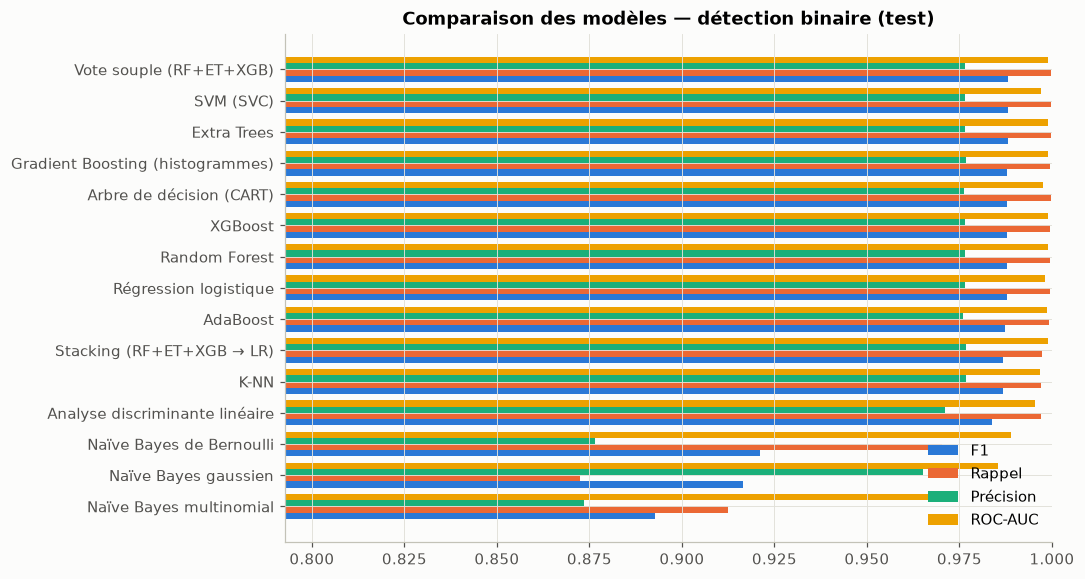

In [9]:
s = bt.drop(index=[i for i in bt.index if 'Zero-R' in i]).sort_values('f1')
fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(s)); h = 0.2
for k, (m, lab) in enumerate([('f1', 'F1'), ('recall', 'Rappel'), ('precision', 'Précision'), ('roc_auc', 'ROC-AUC')]):
    ax.barh(y + (k - 1.5) * h, s[m], height=h, label=lab, color=V.SERIES[k])
ax.set_yticks(y, s.index); ax.set_xlim(max(0, s.f1.min() - 0.1), 1.0); ax.legend(loc='lower right')
ax.set_title('Comparaison des modèles — détection binaire (test)'); V.save(fig, '03_model_comparison_binary'); plt.show()

## 5. Courbes ROC et Précision-Rappel

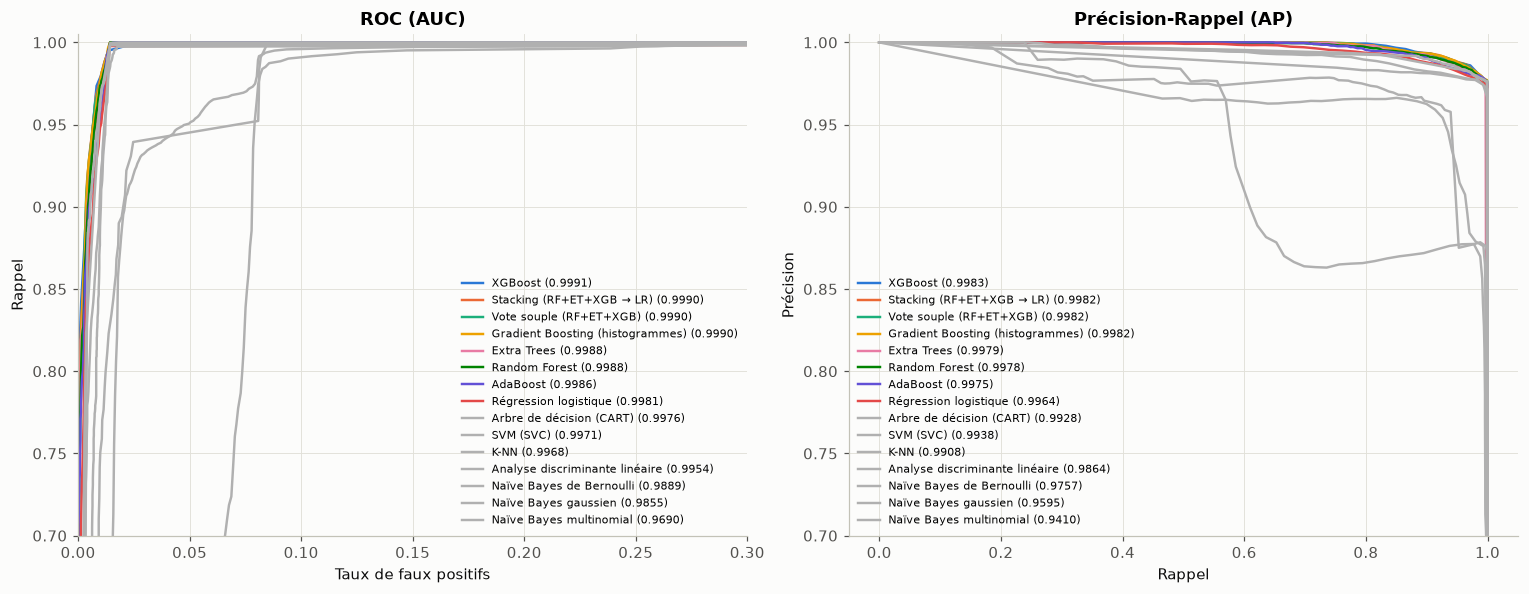

Zoom sur la zone utile (FPR < 30 %) : toutes les courbes sont proches du coin supérieur gauche.


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
order = bt.sort_values('roc_auc', ascending=False)
for i, (name, r) in enumerate(order.iterrows()):
    c = curves.get(f"binary|full|{r['key']}", {})
    if 'roc' not in c: continue
    col = V.SERIES[i % 8] if i < 8 else '#b0b0b0'
    axes[0].plot(c['roc']['fpr'], c['roc']['tpr'], color=col, lw=1.6, label=f"{name} ({r.roc_auc:.4f})")
    axes[1].plot(c['pr']['recall'], c['pr']['precision'], color=col, lw=1.6, label=f"{name} ({r.pr_auc:.4f})")
axes[0].plot([0, 1], [0, 1], ':', color='#898781'); axes[0].set_xlabel('Taux de faux positifs'); axes[0].set_ylabel('Rappel')
axes[0].set_title('ROC (AUC)'); axes[0].legend(fontsize=7, loc='lower right')
axes[1].set_xlabel('Rappel'); axes[1].set_ylabel('Précision'); axes[1].set_title('Précision-Rappel (AP)'); axes[1].legend(fontsize=7, loc='lower left')
axes[0].set_xlim(0, 0.3); axes[0].set_ylim(0.7, 1.005); axes[1].set_ylim(0.7, 1.005)
plt.tight_layout(); V.save(fig, '03_roc_pr_curves'); plt.show()
print('Zoom sur la zone utile (FPR < 30 %) : toutes les courbes sont proches du coin supérieur gauche.')

## 6. Grille des matrices de confusion (binaire)

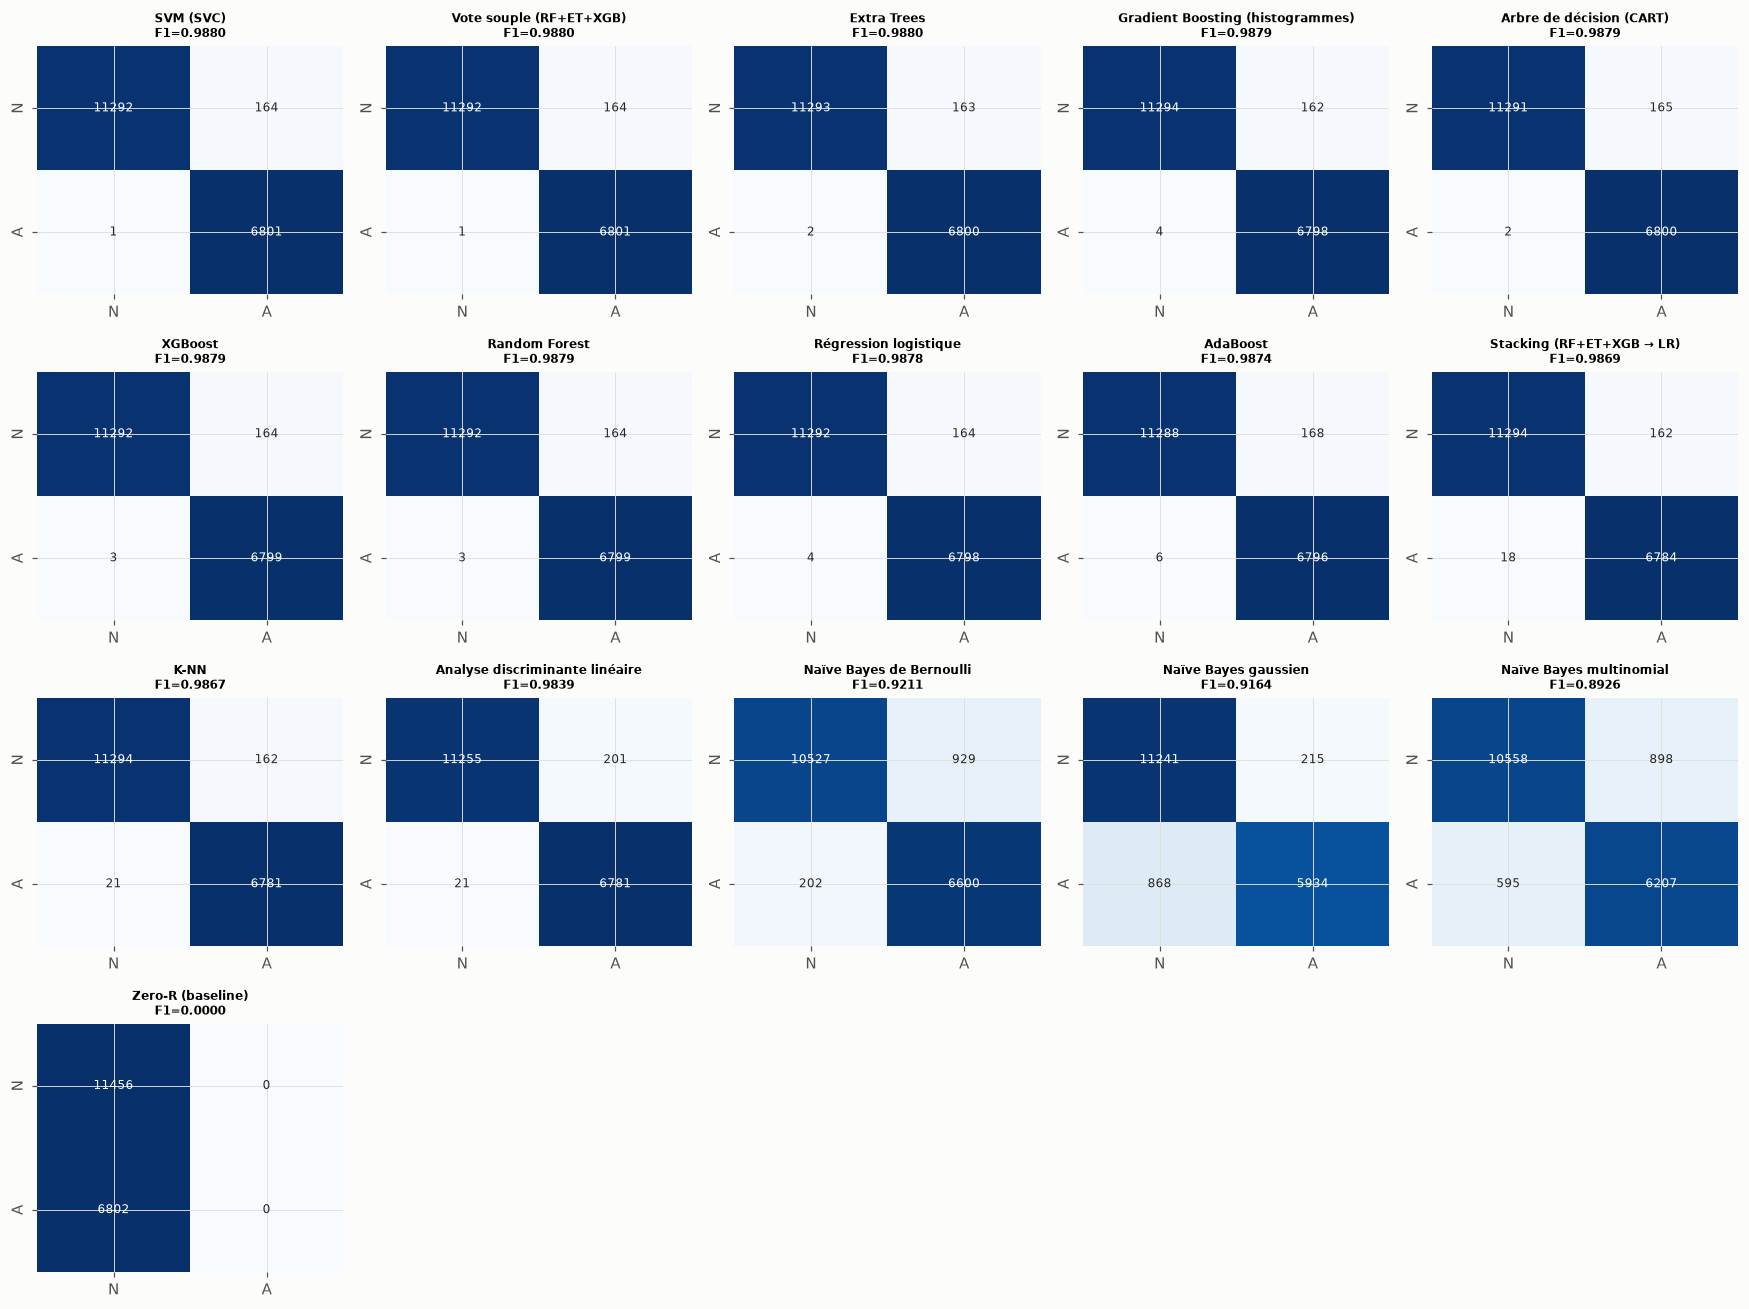

In [11]:
keys = bt.sort_values('f1', ascending=False)
n = len(keys); ncol = 5; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 3 * nrow))
for ax, (name, r) in zip(axes.ravel(), keys.iterrows()):
    cm = np.array(curves[f"binary|full|{r['key']}"]['confusion'])
    sns.heatmap(cm / cm.sum(1, keepdims=True), annot=cm, fmt='d', cmap=V.SEQ_CMAP, vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=['N', 'A'], yticklabels=['N', 'A'], annot_kws={'size': 8})
    ax.set_title(f"{name}\nF1={r.f1:.4f}", fontsize=8)
for ax in axes.ravel()[n:]: ax.axis('off')
plt.tight_layout(); V.save(fig, '03_confusion_grid_binary'); plt.show()

## 7. Analyse par famille d'algorithmes (résultats des recherches d'hyperparamètres)

Les tables complètes de la CV sont dans `results/tables/cv_binary_full_<modèle>.csv`.

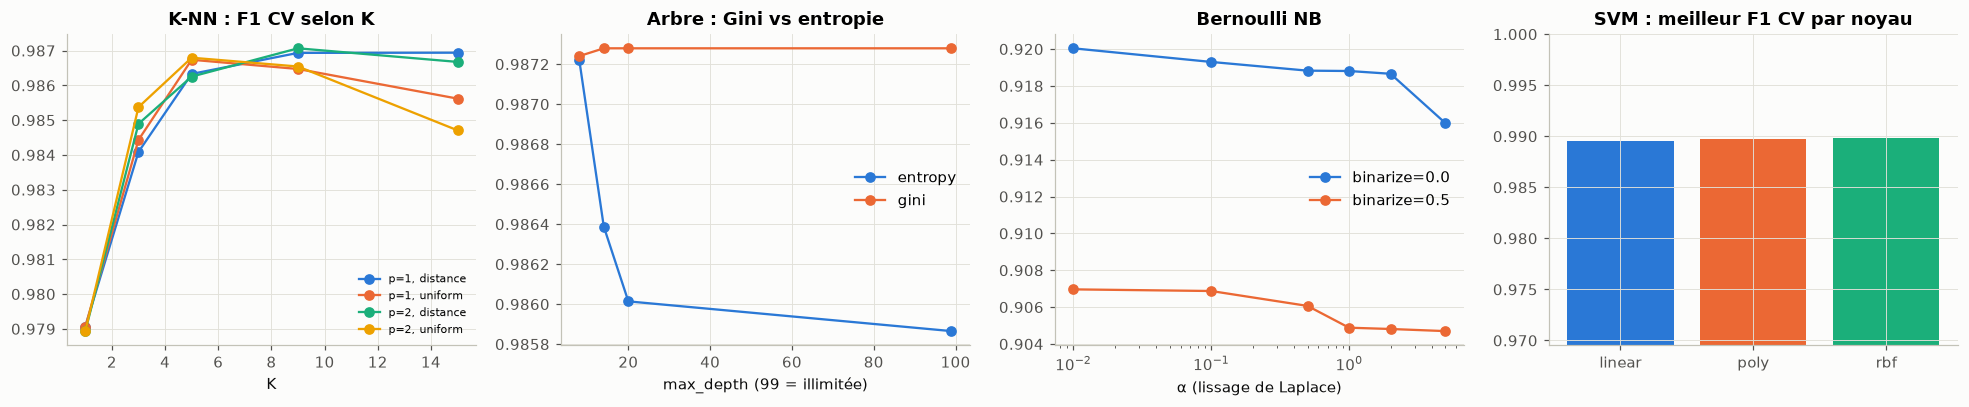

knn              {'n_neighbors': 9, 'p': 2, 'weights': 'distance'}
decision_tree    {'ccp_alpha': 0.0001, 'criterion': 'gini', 'max_depth': 14, 'min_samples_leaf': 1}
random_forest    {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 14, 'class_weight': 'balanced'}
gaussian_nb      {'var_smoothing': 1e-05}
bernoulli_nb     {'alpha': 0.01, 'binarize': 0.0}
multinomial_nb   {'alpha': 0.01}
svm              {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
xgboost          {'colsample_bytree': 0.9692763545078751, 'learning_rate': 0.03005384349946412, 'max_depth': 7, 'min_child_weight': 5, 'n_estimators': 360, 'reg_lambda': 0.4059611610484306, 'subsample': 0.8574269294896713}


In [12]:
def cv(key, task='binary'):
    return pd.read_csv(C.METRICS_DIR / f'cv_{task}_full_{key}.csv')
k = cv('knn'); dt = cv('decision_tree'); nb = cv('bernoulli_nb'); svm = cv('svm')
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for (p, w), g in k.groupby(['param_clf__p', 'param_clf__weights']):
    axes[0].plot(g.param_clf__n_neighbors, g.mean_test_f1, marker='o', label=f"p={p}, {w}")
axes[0].set_xlabel('K'); axes[0].set_title('K-NN : F1 CV selon K'); axes[0].legend(fontsize=7)
for crit, g in dt.groupby('param_clf__criterion'):
    gg = g.groupby(g.param_clf__max_depth.fillna(99))['mean_test_f1'].max()
    axes[1].plot(gg.index.astype(int), gg.values, marker='o', label=crit)
axes[1].set_xlabel('max_depth (99 = illimitée)'); axes[1].set_title('Arbre : Gini vs entropie'); axes[1].legend()
for b, g in nb.groupby('param_clf__binarize'):
    axes[2].semilogx(g.param_clf__alpha, g.mean_test_f1, marker='o', label=f'binarize={b}')
axes[2].set_xlabel('α (lissage de Laplace)'); axes[2].set_title('Bernoulli NB'); axes[2].legend()
sv = svm.groupby('param_clf__kernel')['mean_test_f1'].max()
axes[3].bar(sv.index, sv.values, color=V.SERIES[:len(sv)]); axes[3].set_ylim(sv.min() - 0.02, 1)
axes[3].set_title('SVM : meilleur F1 CV par noyau')
plt.tight_layout(); V.save(fig, '03_hyperparameter_studies'); plt.show()
for key in ['knn', 'decision_tree', 'random_forest', 'gaussian_nb', 'bernoulli_nb', 'multinomial_nb', 'svm', 'xgboost']:
    print(f"{key:<16}", reg['models']['full']['binary'][key]['params'])

## 8. Tâche multi-classe (10 catégories)

,family,cv_common_mean,cv_mean,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,roc_auc_ovr,mcc
model,,,,,,,,,,,
Stacking (RF+ET+XGB → LR),Extension — méta-ensemble,0.6660,0.6660,0.9033,0.7792,0.7636,0.7792,0.7674,0.9082,0.9868,0.8366
Gradient Boosting (histogrammes),Extension — boosting,0.6423,0.6728,0.8853,0.7132,0.7016,0.7132,0.6919,0.8913,0.9812,0.8077
Random Forest,Cours — ensembles (bagging),0.6642,0.6909,0.8831,0.7168,0.7045,0.7168,0.6915,0.8932,0.9778,0.8044
Vote souple (RF+ET+XGB),Extension — méta-ensemble,0.6640,0.6640,0.8813,0.7043,0.7076,0.7043,0.6908,0.8917,0.9786,0.8010
Extra Trees,Extension — ensembles,0.6530,0.6723,0.8794,0.6962,0.6992,0.6962,0.6851,0.8911,0.9746,0.7976
Arbre de décision (CART),Cours — arbres,0.6136,0.6761,0.8845,0.7053,0.7095,0.7053,0.6837,0.8887,0.9681,0.8069
XGBoost,Extension — boosting,0.6483,0.6777,0.8838,0.6890,0.6932,0.6890,0.6825,0.8904,0.9816,0.8042
K-NN,Cours — paresseux,0.5575,0.5874,0.8619,0.5772,0.6032,0.5772,0.5856,0.8587,0.8808,0.7649
Régression logistique,Extension — linéaire,0.5530,0.5721,0.8623,0.5716,0.6121,0.5716,0.5760,0.8628,0.9732,0.7666


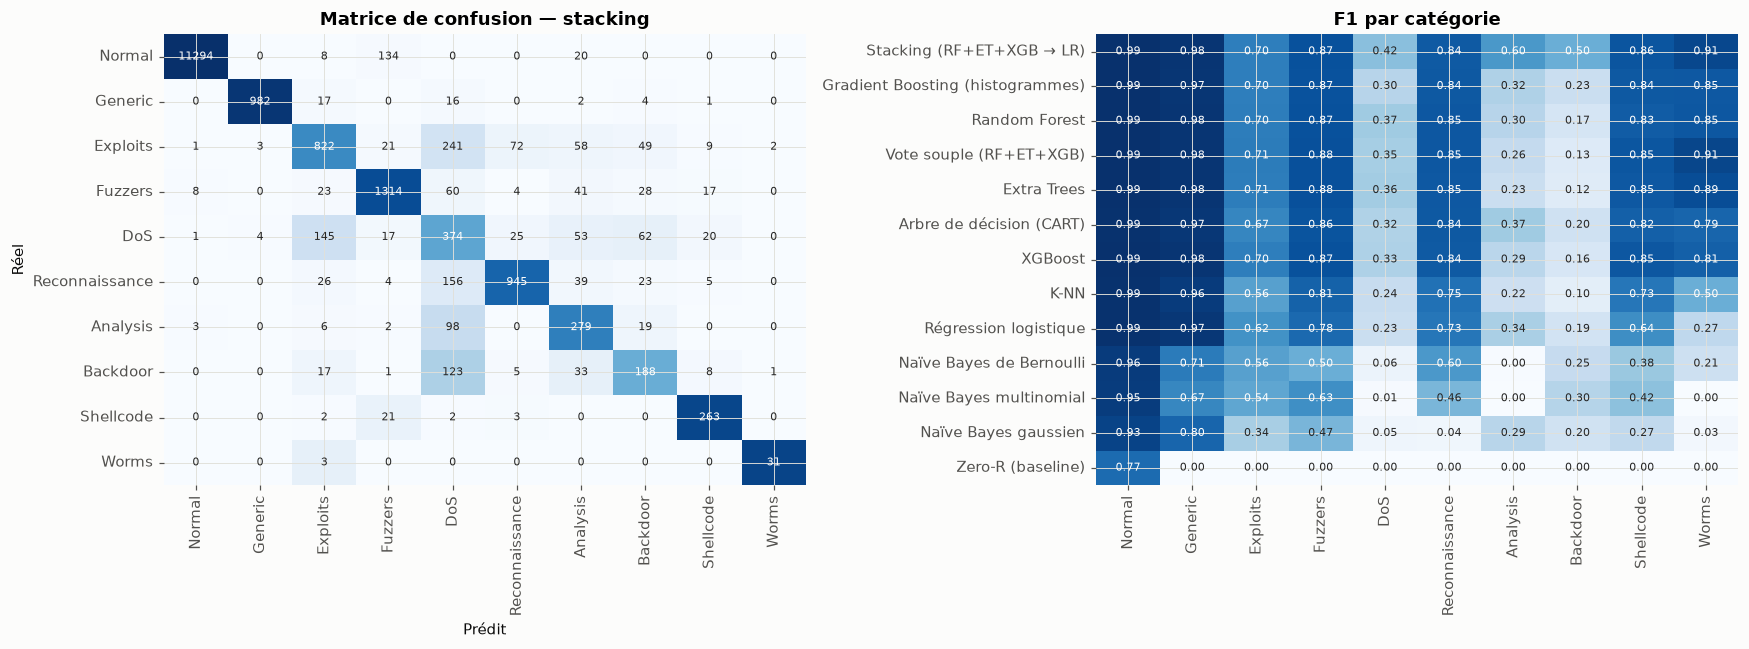

In [13]:
mt = table('multiclass')
display(mt[['family', 'cv_common_mean', 'cv_mean', 'accuracy', 'balanced_accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'f1_weighted', 'roc_auc_ovr', 'mcc']]
        .sort_values('f1_macro', ascending=False).round(4))
best_m = reg['best']['full']['multiclass']
cm = np.array(curves[f'multiclass|full|{best_m}']['confusion'])
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=cm, fmt='d', cmap=V.SEQ_CMAP, ax=axes[0], cbar=False,
            xticklabels=reg['class_names'], yticklabels=reg['class_names'], annot_kws={'size': 7})
axes[0].set_xlabel('Prédit'); axes[0].set_ylabel('Réel'); axes[0].set_title(f'Matrice de confusion — {best_m}')
pc = pd.DataFrame({r['model']: {c: v['f1-score'] for c, v in r['per_class'].items()} for r in reg['metrics']['full']['multiclass'] if r.get('per_class')}).T
sns.heatmap(pc.loc[pc.mean(1).sort_values(ascending=False).index], annot=True, fmt='.2f', cmap=V.SEQ_CMAP, vmin=0, vmax=1, ax=axes[1], cbar=False, annot_kws={'size': 7})
axes[1].set_title('F1 par catégorie'); plt.tight_layout(); V.save(fig, '03_multiclass_results'); plt.show()

**Analyse des erreurs :** *Normal*, *Generic* et *Reconnaissance* sont bien reconnues ; **DoS, Exploits, Analysis
et Backdoor** sont confondues entre elles. Ce n'est pas un défaut des modèles : ces catégories partagent des
vecteurs de features **identiques** (cf. notebook 01 : 8 053 vecteurs en conflit d'étiquette). La thèse
de N. Moustafa et la littérature font le même constat. Le F1-macro est donc borné bien en dessous du F1 binaire.

## 9. Profil portable (sans TTL)

In [14]:
pt = pd.concat({'binaire': table('binary', 'portable')[['cv_mean', 'f1', 'recall', 'roc_auc']],
                'multi-classe': table('multiclass', 'portable')[['cv_mean', 'f1_macro', 'accuracy']]}, axis=1)
display(pt.round(4))

binaire                         multi-classe                  
                         cv_mean      f1  recall roc_auc      cv_mean f1_macro accuracy
model                                                                                  
Zero-R (baseline)         0.0000  0.0000  0.0000  0.5000       0.0771   0.0771   0.6275
K-NN                      0.9848  0.9849  0.9943  0.9956       0.5729   0.5772   0.8581
Arbre de décision (CART)  0.9844  0.9863  0.9982  0.9975       0.6554   0.6471   0.8820
Random Forest             0.9866  0.9874  0.9990  0.9988       0.6672   0.6616   0.8752
Naïve Bayes gaussien      0.8833  0.8804  0.8999  0.9296       0.3073   0.3109   0.6085
XGBoost                   0.9861  0.9869  0.9979  0.9990       0.6633   0.6691   0.8801

## 10. Choix du seuil de décision

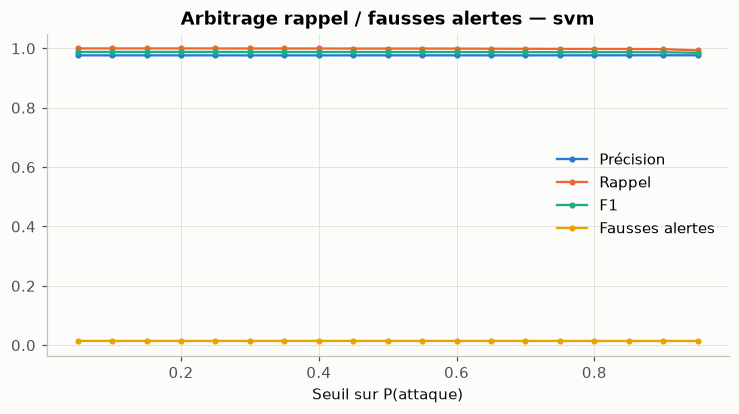

,threshold,precision,recall,f1,false_alarm_rate,accuracy
0,0.05,0.9765,0.9999,0.9880,0.0143,0.9910
3,0.20,0.9765,0.9999,0.9880,0.0143,0.9910
6,0.35,0.9764,0.9996,0.9879,0.0143,0.9909
9,0.50,0.9764,0.9994,0.9878,0.0143,0.9908
12,0.65,0.9764,0.9988,0.9875,0.0143,0.9906
15,0.80,0.9766,0.9981,0.9872,0.0142,0.9904
18,0.95,0.9767,0.9932,0.9849,0.0141,0.9887


In [15]:
bk = reg['best']['full']['binary']
thr = pd.DataFrame(curves[f'binary|full|{bk}']['thresholds'])
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, (c, l) in enumerate([('precision', 'Précision'), ('recall', 'Rappel'), ('f1', 'F1'), ('false_alarm_rate', 'Fausses alertes')]):
    ax.plot(thr.threshold, thr[c], marker='o', ms=3, label=l, color=V.SERIES[i])
ax.set_xlabel('Seuil sur P(attaque)'); ax.legend(); ax.set_title(f'Arbitrage rappel / fausses alertes — {bk}')
V.save(fig, '03_threshold_analysis'); plt.show()
display(thr.round(4).iloc[::3])

## 11. Comparaison statistique des modèles

Une différence de 0,001 de F1 peut être due au hasard du découpage. On teste :
- **Friedman** (H₀ : tous les modèles ont le même rang moyen sur les 5 plis communs) puis distance critique de **Nemenyi** ;
- **Wilcoxon signé** meilleur vs chaque autre modèle, correction de **Holm** ;
- **McNemar** entre les deux meilleurs sur le test (H₀ : mêmes taux d'erreur sur les flux où ils divergent).

In [16]:
from src import run_analysis as RA
stats = RA.model_statistics(test)          # Friedman + Nemenyi, Wilcoxon-Holm, McNemar
for task, st in stats.items():
    fr, mc = st['friedman'], st['mcnemar']
    print(f"[{task}] Friedman χ²={fr['chi2']:.2f}, p={fr['p_value']:.2e}, CD Nemenyi={fr['critical_difference']:.2f}")
    print(f"        McNemar {mc['model_a']} vs {mc['model_b']} : b={mc['b']}, c={mc['c']}, p={mc['p_value']:.3g}")
    display(pd.Series(fr['mean_ranks'], name='rang moyen').to_frame().T.round(2))

[binary] Friedman χ²=60.38 p=1.01e-07 | McNemar svm vs voting p=1


[multiclass] Friedman χ²=50.82 p=4.46e-07 | McNemar stacking vs random_forest p=6.3e-43
[binary] Friedman χ²=60.38, p=1.01e-07, CD Nemenyi=9.59
        McNemar svm vs voting : b=2, c=2, p=1


,svm,voting,extra_trees,random_forest,stacking,logistic_regression,adaboost,hist_gb,xgboost,knn,lda,decision_tree,gaussian_nb,bernoulli_nb,multinomial_nb
rang moyen,2.7,2.8,4.1,4.4,5.4,5.5,5.8,7.2,7.3,10.2,11.2,11.4,13.0,14.0,15.0


[multiclass] Friedman χ²=50.82, p=4.46e-07, CD Nemenyi=7.45
        McNemar stacking vs random_forest : b=541, c=173, p=6.3e-43


,random_forest,stacking,voting,extra_trees,xgboost,hist_gb,decision_tree,knn,logistic_regression,bernoulli_nb,multinomial_nb,gaussian_nb
rang moyen,2.4,2.4,2.4,3.8,4.8,5.4,7.0,8.2,8.6,10.0,11.0,12.0


## 12. Courbes d'apprentissage

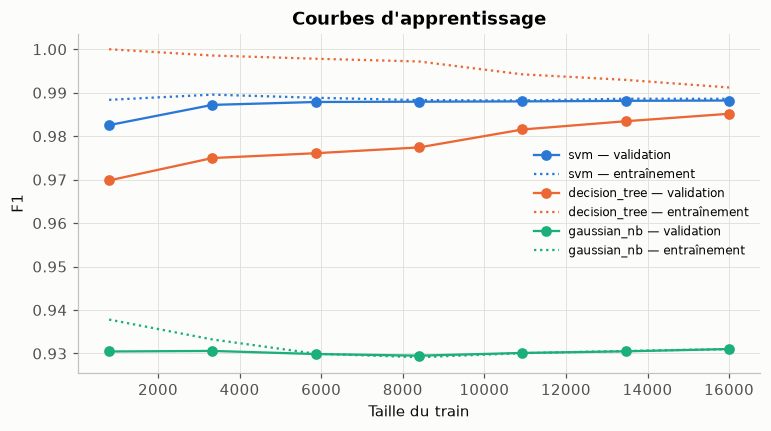

In [17]:
lc = RA.learning_curves(train)            # mis en cache dans reports/metrics/learning_curves.json
fig, ax = plt.subplots(figsize=(8, 4))
for i, (k, d) in enumerate(lc.items()):
    ax.plot(d['sizes'], d['val_mean'], marker='o', color=V.SERIES[i], label=f'{k} — validation')
    ax.plot(d['sizes'], d['train_mean'], ls=':', color=V.SERIES[i], label=f'{k} — entraînement')
ax.set_xlabel("Taille du train"); ax.set_ylabel('F1'); ax.legend(fontsize=8); ax.set_title("Courbes d'apprentissage")
V.save(fig, '03_learning_curves'); plt.show()

## 13. Conclusion

- Tous les modèles battent largement **Zero-R** (F1 = 0 : il ne détecte aucune attaque).
- Les **ensembles d'arbres** (XGBoost, Random Forest, Extra Trees, HistGB, vote, stacking) dominent ; K-NN et
  l'arbre CART sont très proches. Les tests de Friedman/Nemenyi/McNemar indiquent quels écarts sont réels.
- Naïve Bayes est nettement en retrait : l'hypothèse d'indépendance conditionnelle est violée par des
  features très corrélées (cf. Spearman).
- Le **profil portable** perd peu en binaire : l'information n'est pas uniquement dans le TTL.
- Modèles déployés : `models/binaire/` et `models/multiclasse/` (meilleurs en CV), seuil réglable dans l'application.